# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

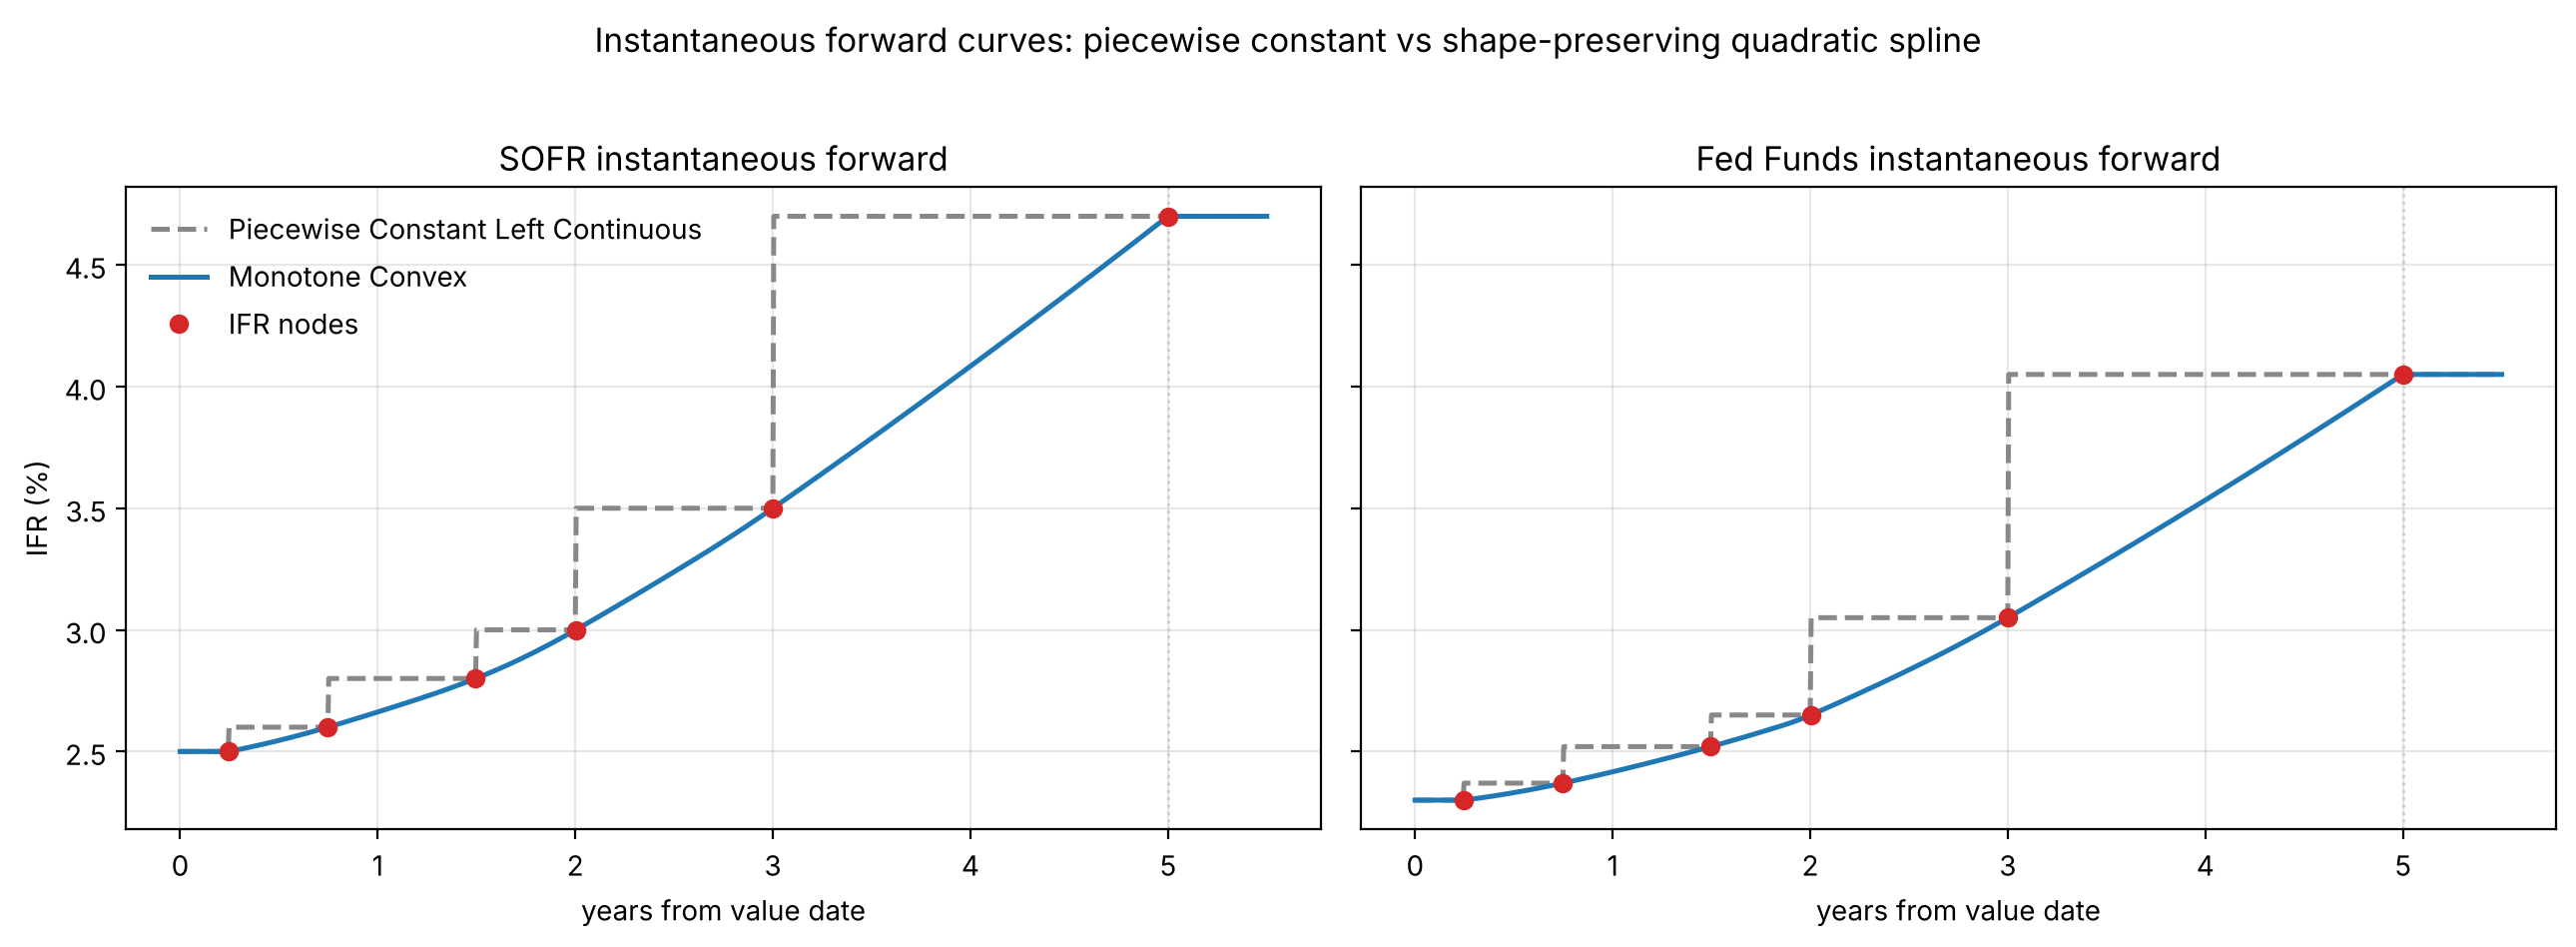

Shape check on the interpolated curve (between first and last node):



  SOFR       passes through nodes to 0.0e+00
             monotone increasing : True
             convex              : True
             stays within [2.500%, 4.700%], nodes span [2.500%, 4.700%]


  Fed Funds  passes through nodes to 0.0e+00
             monotone increasing : True
             convex              : True
             stays within [2.300%, 4.050%], nodes span [2.300%, 4.050%]

  funding    one node -> constant {0.0005} (single value: True)


In [2]:
import matplotlib.pyplot as plt
import numpy as np

from fixedincomelib.market.registries import FundingIdentifierRegistry, IndexRegistry

VALUE_DATE = "2026-01-02"
METHODS = ["PIECEWISE_CONSTANT_LEFT_CONTINUOUS", "MONOTONE_CONVEX"]


def build_model(method):
    bms = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs,
                                   "INTERPOLATION METHOD": method,
                                   "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs
    ])
    return qfCreateModel(VALUE_DATE, "YIELD_CURVE", data_collection, bms)


# Pull the interpolator off the built model rather than rebuilding one here, so the
# curve being plotted is the same object the pricing cells discount with.
models = {m: build_model(m) for m in METHODS}


def curve(method, index):
    """The interpolator the model itself will discount with.

    A projection curve is keyed by its QuantLib index, a funding curve by its
    funding identifier, so the lookup has to try both.
    """
    try:
        key = IndexRegistry().get(index)
    except KeyError:
        key = FundingIdentifierRegistry().get(index)
    return models[method].retrieve_model_component(key)


# Read the node times off the model rather than recomputing them. qfAccrued's default
# basis is not the one the curve is built on (0.2500 against 0.2466 at the first node),
# so recomputing would put the markers in the wrong place and test the spline at points
# that are not its nodes.
node_times = np.asarray(curve(METHODS[1], "SOFR-1B").state_data[0], dtype=float)


grid = np.linspace(0.0, node_times[-1] + 0.5, 1200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)

for ax, (index, quotes, name) in zip(
    axes,
    [("SOFR-1B", sofr_quotes, "SOFR"), ("FF-1B", ff_quotes, "Fed Funds")],
):
    for method, style, colour in zip(METHODS, ["--", "-"], ["#888888", "#1f77b4"]):
        f = curve(method, index).state_data_interpolator
        ax.plot(grid, [f.interpolate(x) * 100 for x in grid], style, color=colour,
                lw=1.8, label=method.replace("_", " ").title())
    ax.plot(node_times, quotes["values"].to_numpy() * 100, "o", color="#d62728",
            ms=6, zorder=5, label="IFR nodes")
    ax.axvline(node_times[-1], color="#cccccc", lw=1, ls=":")
    ax.set_title(f"{name} instantaneous forward")
    ax.set_xlabel("years from value date")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("IFR (%)")
axes[0].legend(loc="upper left", frameon=False)
fig.suptitle("Instantaneous forward curves: piecewise constant vs shape-preserving "
             "quadratic spline", y=1.02)
fig.tight_layout()
plt.show()

# The claims in the text below are checked rather than asserted by eye.
print("Shape check on the interpolated curve (between first and last node):\n")
for index, quotes, name in [("SOFR-1B", sofr_quotes, "SOFR"),
                            ("FF-1B", ff_quotes, "Fed Funds")]:
    f = curve("MONOTONE_CONVEX", index).state_data_interpolator
    values = quotes["values"].to_numpy()
    fine = np.linspace(node_times[0], node_times[-1], 200_001)
    y = np.array([f.interpolate(x) for x in fine])

    node_err = max(abs(f.interpolate(t) - v) for t, v in zip(node_times, values))
    first, second = np.diff(y), np.diff(y, 2)
    print(f"  {name:10s} passes through nodes to {node_err:.1e}")
    print(f"  {'':10s} monotone increasing : {bool((first >= -1e-15).all())}")
    print(f"  {'':10s} convex              : {bool((second >= -1e-12).all())}")
    print(f"  {'':10s} stays within [{y.min() * 100:.3f}%, {y.max() * 100:.3f}%], "
          f"nodes span [{values.min() * 100:.3f}%, {values.max() * 100:.3f}%]")

# A one-node curve must be flat, which is what the funding component is.
funding = curve("MONOTONE_CONVEX", "SOFR-1B-FLAT").state_data_interpolator
flat = {round(funding.interpolate(x), 12) for x in [0.0, 0.5, 1.0, 3.0, 20.0]}
print(f"\n  funding    one node -> constant {flat} (single value: {len(flat) == 1})")

### Method, and how the shape is guaranteed

**What is being interpolated.** Hagan and West build their monotone convex curve from
*discrete* forwards: their defining constraint is that the curve's average over each
interval reproduces the input, and the instantaneous forwards at the nodes come out of
the construction. Here the inputs are the instantaneous forwards themselves and have to
be matched exactly, so that constraint is not available and their formulae do not carry
over unchanged. What does carry over is the device that makes their method work: allow
one extra breakpoint inside an interval, so each piece can be shaped on its own rather
than a single polynomial having to satisfy every condition at once. That is Schumaker's
shape-preserving quadratic spline, and it is what `Interpolator1DMonotoneConvex`
implements.

**Construction.** On $[t_i, t_{i+1}]$, with $h = t_{i+1} - t_i$ and secant slope
$D = (f_{i+1} - f_i)/h$, the spline is two quadratics joined at an interior knot. Matching
the right-hand value forces the slope at the knot,

$$\bar m = 2D - \frac{a\,m_i + b\,m_{i+1}}{h},$$

where $a$ and $b$ are the two sub-lengths. Both pieces are quadratic and the slope is
continuous at the knot, so the derivative is **piecewise linear**, running
$m_i \to \bar m \to m_{i+1}$ across the interval. Everything below is a statement about
that path, which is why the shape is easy to control and the integral is exact.

**Monotonicity and convexity.** Interior node slopes are a length-weighted average of the
two adjacent secants, so each $m_i$ lies *between* them. On any interval the node slopes
therefore straddle that interval's secant, and with Schumaker's knot placement the algebra
collapses to $\bar m = D$ exactly. The derivative path is then $m_i \to D \to m_{i+1}$:

- **monotone**, because all three share the sign of $D$, so $f'$ never changes sign;
- **convex**, because convex data has increasing secants, the slopes inherit
  $m_i \le D \le m_{i+1}$, and a non-decreasing derivative *is* convexity.

Positivity comes free: with no overshoot the curve stays inside $[f_i, f_{i+1}]$ on each
interval, so positive inputs give a positive curve. This matters for a forward curve in a
way it does not for a generic spline, and it is the deficiency Hagan and West set out to
fix.

**Data that cannot satisfy every condition.** Where consecutive secants have opposite
signs the data has a local extremum, and *no* interpolant through those points can be
monotone there. The slope at that node is set to zero, turning the extremum into a smooth
turning point instead of letting the spline overshoot and manufacture a forward rate the
data never implied. The curve stays continuous, still interpolates, and stays monotone on
every interval that is monotone in the data; only convexity is given up, and only locally.
A flat segment ($D = 0$) likewise forces both of its slopes to zero, so the piece is
exactly constant rather than drifting between equal endpoints. Degenerate inputs follow
the same logic: one node gives a constant curve (which is what the funding component
needs), two give a straight line, and repeated node times are collapsed first.

**Why the PVs move.** Piecewise constant puts the whole of each interval at the right-hand
node's rate, so against rising data it systematically over-discounts early and the curve
sits above the smooth one for most of each interval. The spline instead ramps between
nodes. For the SOFR data, which is increasing and convex, the spline's integrated forward
to a given date is lower, so discount factors are higher. That raises the PV of the
receive-fixed FRA and swap. The basis swap moves the other way because it is a
*difference* of two projections: SOFR and Fed Funds are re-shaped by different amounts, and
the leg-1 projection loses more than leg 2 gains.

In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3266.283360992791
Student minus PCP: 357.9967217548274


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070125


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12840.24847283293
Student minus PCP: 6617.730959762805


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181353


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7626.942535473652
Student minus PCP: -724.4063727077009
